# M09-3 | ORT's Own PTQ Tool vs PT2E: Same QDQ ONNX, Where the Two Paths Differ

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m09_onnx_runtime/03_ort_quant_compare.ipynb)

The QDQ ONNX in M09-1 and M09-2 were both "quantize in PyTorch with PT2E first, then export". ORT also has its own PTQ tool, which takes an fp32 ONNX directly and inserts Q/DQ on the ONNX graph:

```text
PT2E path: PyTorch model → PT2E → torch.onnx.export             QDQ ONNX
ORT path : PyTorch model → torch.onnx.export → quantize_static   QDQ ONNX
```

- **A.** The default settings of `quantize_static`, and the graph it produces.
- **B.** Accuracy: PT2E's QDQ ONNX vs. two settings of the ORT tool.
- **C.** Another output of the same tool: QOperator format.

In [ ]:
#| include: false
# On Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# On your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m09_onnx_runtime")

In [1]:
import inspect

import onnxruntime as ort
import torch
from onnxruntime.quantization import QuantFormat, quantize_static

from common.pt2e import quiet  # must be imported before onnx/torchao
from common.data import make_loader, trained_tiny_net
from common.env import env_summary
from common.graph_utils import sqnr
from common.models import example_inputs
from common.onnx_utils import onnx_op_counts, ort_quantize, ort_run, ort_session, to_onnx, xnnpack_qdq
from common.viz import draw_onnx, table

quiet()
_ = torch.manual_seed(0)
print(env_summary() + f" | onnxruntime {ort.__version__}")

Darwin arm64｜torch 2.14.0｜threads=4｜mkldnn=False｜nnpack=True｜onnxruntime 1.30.0


Inputs for both sides (same as M09-1):

- fp32 ONNX: `torch.onnx.export(fp32 model, x, dynamo=True)` (`to_onnx`), the input to `quantize_static`.
- PT2E's QDQ ONNX: the Q/DQ graph from PT2E (`xnnpack_qdq`), then `torch.onnx.export`.

Both sides use the same calibration data (`common.data.calibration_batches`, 128 samples).

In [2]:
model = trained_tiny_net()
x = example_inputs()
fp32_onnx = to_onnx(model, x)
pt2e_onnx = to_onnx(xnnpack_qdq(model, x), x)

## A. The Default Settings of `quantize_static`, and the Graph It Produces

`inspect.signature` reads out the defaults of `quantize_static`, to compare with the PT2E side's settings (torchao test-version XNNPACKQuantizer):

In [3]:
params = inspect.signature(quantize_static).parameters
pt2e = {"quant_format": "QDQ (the export is QDQ)", "activation_type": "int8 per-tensor affine",
        "weight_type": "int8 symmetric [-127, 127]", "per_channel": "True (xnnpack_qdq passes is_per_channel=True)",
        "calibrate_method": "HistogramObserver"}
table([[k, str(params[k].default), v] for k, v in pt2e.items()], ["Parameter", "ORT default", "PT2E (xnnpack_qdq)"])

參數,ORT 預設,PT2E（xnnpack_qdq）
quant_format,QDQ,QDQ（匯出就是 QDQ）
activation_type,QInt8,int8 per-tensor affine
weight_type,QInt8,"int8 對稱 [-127, 127]"
per_channel,False,True（xnnpack_qdq 傳 is_per_channel=True）
calibrate_method,CalibrationMethod.MinMax,HistogramObserver


ORT's activation defaults to asymmetric and weight to symmetric, set in `ActivationSymmetric` / `WeightSymmetric` of `extra_options`.

`quantize_static(fp32 ONNX, output path, calibration data)` uses all defaults. This project's `ort_quantize` wraps three things:

- The tool can only write a file, so the output goes through a temp file and is read back.
- The tool modifies the `ModelProto` passed in (turning the weights into external data pointing at a temp file), so passing the same object a second time cannot be read; hence each call passes a `copy.deepcopy`.
- The tool's warnings go through Python's root logger; they are collected and returned to the caller (section C prints one).

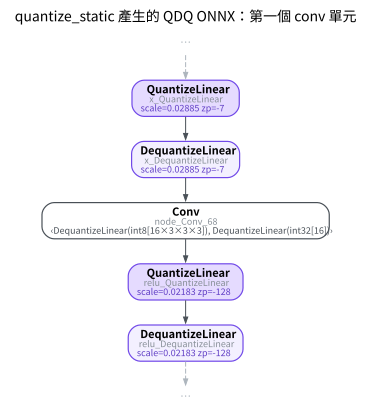

In [4]:
ort_default, _ = ort_quantize(fp32_onnx)
first_conv = next(n.name for n in ort_default.graph.node if n.op_type == "Conv")
draw_onnx(ort_default, focus=first_conv, hops=2, title="QDQ ONNX produced by quantize_static: first conv unit")

In [5]:
c_fp32, c_ort = onnx_op_counts(fp32_onnx), onnx_op_counts(ort_default)
print(f"Relu: {c_fp32.get('Relu', 0)} in fp32 ONNX → {c_ort.get('Relu', 0)} after quantize_static")
assert c_fp32["Relu"] > 0 and c_ort.get("Relu", 0) == 0

Relu：fp32 ONNX 4 個 → quantize_static 之後 0 個


Compared with the first conv unit exported from PT2E in section A of M09-1, there are three differences:

1. **No Relu**: the tool removes the Relu after the conv at quantization time, leaving the clamp to the following QuantizeLinear's zero point = -128. This is what ORT does only at EXTENDED in M09-2; here it is written into the file.
2. **The bias is already `DequantizeLinear(int32[…])`**: the bias quantization that only happens at BASIC in M09-2 is also written into the file here.
3. **The weight is per-tensor**: the default is `per_channel=False`.

ORT's tool sees only the ONNX graph, but the decisions it makes are the same kind as a PT2E quantizer's: which edges get Q/DQ, with scales computed from calibration data.

## B. Accuracy

All four `.onnx` files run on ORT's CPU EP (default level `ORT_ENABLE_ALL`, `ort_session`) over the same 1024 test samples (same as M05-1):

In [6]:
ort_pc, _ = ort_quantize(fp32_onnx, per_channel=True)
candidates = {
    "fp32 ONNX": fp32_onnx,
    "PT2E → torch.onnx.export": pt2e_onnx,
    "quantize_static: default (per-tensor weight)": ort_default,
    "quantize_static: per_channel=True": ort_pc,
}
xs, ys = zip(*make_loader(n=1024, seed=2, shuffle=False))
x_test, y_test = torch.cat(xs), torch.cat(ys)
with torch.no_grad():
    y_fp32 = model(x_test)
acc, snr = {}, {}
for name, m in candidates.items():
    out = ort_run(ort_session(m), x_test)
    acc[name], snr[name] = (out.argmax(1) == y_test).float().mean().item(), sqnr(y_fp32, out)
table([[name, "-" if name == "fp32 ONNX" else f"{snr[name]:.2f}", f"{acc[name]:.4f}"] for name in candidates],
      ["", "SQNR vs PyTorch fp32 (dB)", "accuracy"])

,對 PyTorch fp32 的 SQNR (dB),accuracy
fp32 ONNX,-,0.7109
PT2E → torch.onnx.export,29.18,0.7061
quantize_static：預設（per-tensor weight）,27.81,0.7129
quantize_static：per_channel=True,29.68,0.7109


In [7]:
quantized = list(candidates)[1:]
n_diff = round((max(acc[n] for n in quantized) - min(acc[n] for n in quantized)) * len(y_test))
print(f"The accuracy of the three quantized versions differs by at most {n_diff} samples (out of {len(y_test)})")
print(f"Highest SQNR: {max(quantized, key=lambda n: snr[n])}; lowest: {min(quantized, key=lambda n: snr[n])}")
assert all(snr[n] > 20 for n in quantized)

三個量化版本的 accuracy 最多差 7 筆（共 1024 筆）
SQNR 最高：quantize_static：per_channel=True；最低：quantize_static：預設（per-tensor weight）


The accuracy of the three quantized versions differs by only a few samples, too small a gap to rank them. The two paths have different settings (the activation observer is Histogram or MinMax; the weight is per-tensor or per-channel), and which of these accounts for the SQNR difference is not broken down here.

The point is the flow rather than the scores: both paths produce QDQ ONNX, and ORT uses the same QDQ node fusion when running them (M09-2).

## C. QOperator format

`quantize_static` has another output format: `quant_format=QuantFormat.QOperator`.

In [8]:
qop, warnings = ort_quantize(fp32_onnx, quant_format=QuantFormat.QOperator)
print("Ops in QOperator format:", dict(onnx_op_counts(qop)))
for w in warnings:
    if "QuantFormat" in w:  # the other two warnings recommend pre-processing first and are unrelated to this section
        print("Warning printed by quantize_static:", w.strip())

QOperator format 的 op： {'QuantizeLinear': 2, 'QLinearConv': 4, 'MaxPool': 2, 'com.microsoft.QLinearAdd': 1, 'DequantizeLinear': 2, 'ReduceMean': 1, 'Reshape': 1, 'com.microsoft.QGemm': 1}
quantize_static 印出的警告： Please use QuantFormat.QDQ for activation type QInt8 and weight type QInt8. Or it will lead to bad performance on x64.


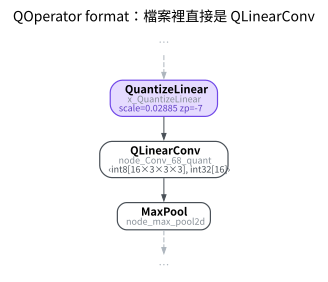

In [9]:
first_qconv = next(n.name for n in qop.graph.node if n.op_type == "QLinearConv")
draw_onnx(qop, focus=first_qconv, hops=1, title="QOperator format: the file contains QLinearConv directly")

QOperator format writes the fused int8 ops (`QLinearConv`, `QLinearAdd`…) straight into the file, which is almost the same as the graph the CPU EP rewrites at `ORT_ENABLE_EXTENDED` in M09-2. ORT's tool itself prints a warning recommending QDQ format for int8 activation + int8 weight.

The two formats differ in "who decides to swap in int8 ops":

| Format | Who decides to swap in int8 ops | Which EPs can run it |
|---|---|---|
| QDQ format | The EP at run time | Any EP (if it does not recognize them, it runs in fp32) |
| QOperator format | The quantization tool | Only EPs that implement these int8 ops |

The "which EPs can run it" column is from the ORT docs; only the CPU EP was verified here. What PT2E exports is always QDQ format.

## Summary

- ORT's `quantize_static` does the same job as PT2E: decide where to insert Q/DQ and compute scales from calibration data. It just does so on the ONNX graph.
- It also folds the Relu and quantizes the bias to int32 into the file; PT2E leaves these to the backend (XNNPACK in M08, ORT in M09-2).
- QDQ format leaves the decision to the EP at run time; QOperator format hard-codes the int8 ops at quantization time.